<a href="https://colab.research.google.com/github/Najibtaufik/transformer-health-index-prediction-Classification-sample-weight-Feature-selection/blob/main/Random_forest_predictions_and_classification_with_simple_weight_and_feature_selection" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
from scipy.stats import zscore
import math

In [ ]:
# Load dataset
df = pd.read_csv('/content/Health Index.csv', sep=';')

# Replace commas with periods
fitur = df.drop(['Health index', 'Label'], axis=1).columns
df[fitur] = df[fitur].replace(',', '.', regex=True).apply(pd.to_numeric, errors='coerce')

# Ensure the Health index is also numeric
df['Health index'] = df['Health index'].replace(',', '.', regex=True).astype(float)

# Drop NaN
df.dropna(inplace=True)


In [ ]:
# Separate features and target
X = df.drop(['Health index', 'Label'], axis=1)
y_reg = df['Health index']
y_class = df['Label']

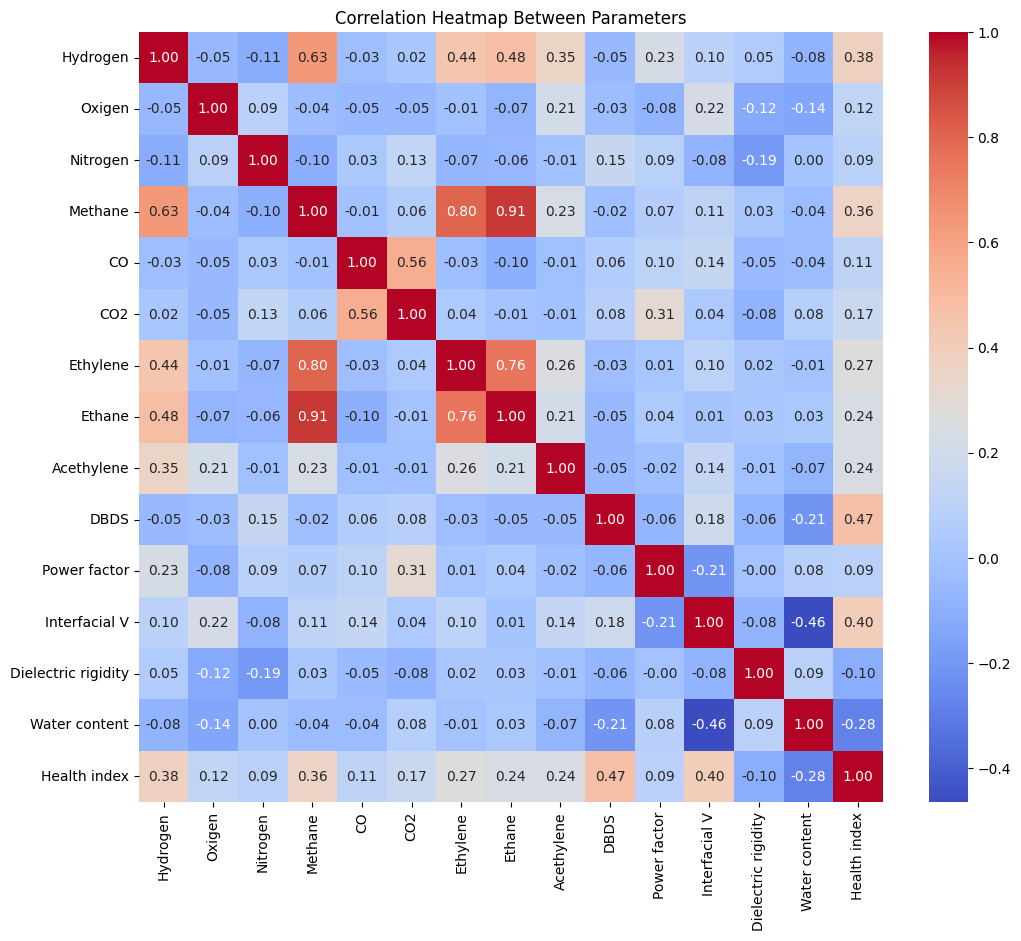

In [ ]:
# Correlation between Parameters
df_numeric = df.select_dtypes(include=['float64', 'int64'])

corr_matrix = df_numeric.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm')
plt.title("Correlation Heatmap Between Parameters")
plt.show()

DBDS             0.468809
Interfacial V    0.400216
Hydrogen         0.377388
Methane          0.361770
Ethylene         0.271504
Acethylene       0.240143
Ethane           0.236507
CO2              0.168777
Water content   -0.281165
dtype: float64


/tmp/ipykernel_849/1131132224.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlation.values, y=correlation.index, palette="viridis")


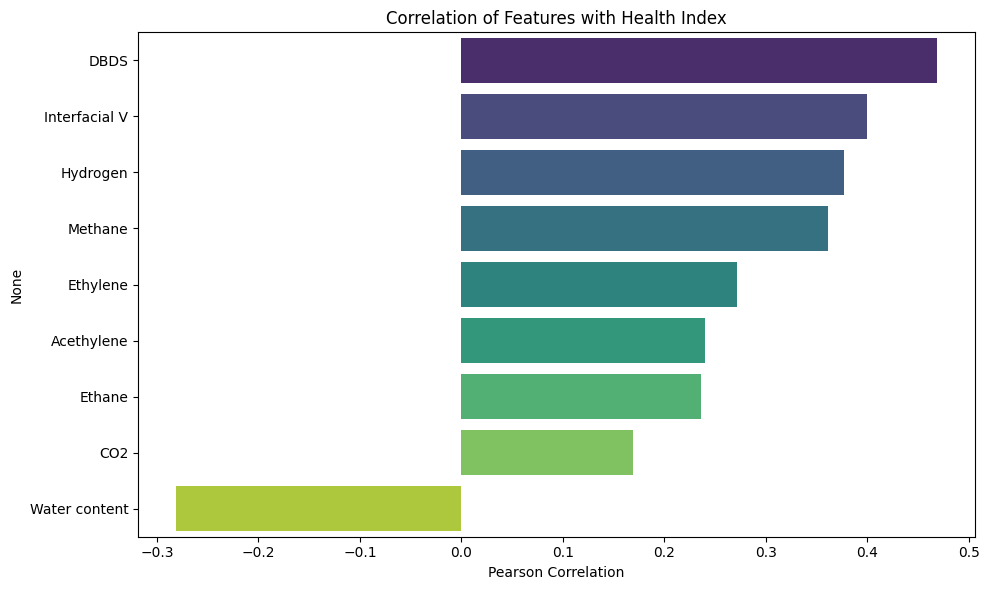

In [22]:
# Calculate the correlation of each feature with the Health index
correlation = X.corrwith(y_reg).sort_values(ascending=False)
print(correlation)

# Visualisasi
plt.figure(figsize=(10, 6))
sns.barplot(x=correlation.values, y=correlation.index, palette="viridis")
plt.title("Correlation of Features with Health Index")
plt.xlabel("Pearson Correlation")
plt.tight_layout()
plt.show()

In [ ]:

# Apply z-score standardization
X_scaled = X.apply(zscore)

# Calculate the mean z-score per column (the result should be very close to 0)
means = X_scaled.mean()
max_exponent = int(np.floor(np.log10(np.max(np.abs(means[means != 0])))))

def to_common_exponent(value, exponent):
    if value == 0:
        return 0
    return value / (10 ** exponent)

mantissas = means.apply(lambda x: to_common_exponent(x, max_exponent))

superscripts = str.maketrans("0123456789-", "⁰¹²³⁴⁵⁶⁷⁸⁹⁻")

exponent_str = str(max_exponent).translate(superscripts)

print("Mean Z-score with equal exponents:")
for param, mantissa in mantissas.items():
    print(f"{param:<20}: {mantissa:7.3f} × 10{exponent_str}")



Mean Z-score with equal exponents:
Hydrogen            :   0.000 × 10⁻¹⁶
Oxigen              :  -0.529 × 10⁻¹⁶
Nitrogen            :  -2.419 × 10⁻¹⁶
Methane             :  -0.302 × 10⁻¹⁶
CO                  :   0.000 × 10⁻¹⁶
CO2                 :  -0.151 × 10⁻¹⁶
Ethylene            :   0.151 × 10⁻¹⁶
Ethane              :   0.151 × 10⁻¹⁶
Acethylene          :  -0.151 × 10⁻¹⁶
DBDS                :  -0.605 × 10⁻¹⁶
Power factor        :   0.000 × 10⁻¹⁶
Interfacial V       :   1.209 × 10⁻¹⁶
Dielectric rigidity :   4.157 × 10⁻¹⁶
Water content       :   0.000 × 10⁻¹⁶


In [ ]:
# calculating the correlation of parameters with 'Health index'
health_index_corr = df.corr(numeric_only=True)['Health index'].abs()
features_to_drop = health_index_corr[
    (health_index_corr < 0.15) &
    (health_index_corr.index != 'Health index') &
    (health_index_corr.index != 'Label')
].index

print("Features removed due to a correlation of less than 0.15 with the 'Health index':")
print(list(features_to_drop))

X = X.drop(columns=features_to_drop)

Features removed due to a correlation of less than 0.15 with the 'Health index':
['Oxigen', 'Nitrogen', 'CO', 'Power factor', 'Dielectric rigidity']


In [ ]:
# Z-score normalization
scaler = StandardScaler()
scaled_features = scaler.fit_transform(X)
scaled_df = pd.DataFrame(scaled_features, columns=X.columns)

print(scaled_df.head())

   Hydrogen    Methane       CO2   Ethylene     Ethane  Acethylene      DBDS  \
0  1.220362  14.988363 -0.209553  12.493229  15.736172   -0.131263  0.042056   
1  6.240833   1.631148 -0.422472  -0.120178   0.651823   -0.142138  0.598976   
2  1.207862   0.131555 -0.326658   0.032574  -0.207301    3.260174 -0.343504   
3  0.347367   0.951933 -0.183826  -0.118665   0.432658   -0.142138  1.498617   
4  1.402861   0.164289  0.139100  -0.120178  -0.113791   -0.135924 -0.343504   

   Interfacial V  Water content  
0       1.063786      -0.952364  
1       1.063786      -0.952364  
2       0.091694      -0.308993  
3      -0.880398      -0.659923  
4       0.901771      -0.776899  


In [ ]:
# Split data
X_train, X_test, y_train_reg, y_test_reg = train_test_split(scaled_df, y_reg, test_size=0.2, random_state=42)

In [ ]:
# Create sample weights based on HI (assign a higher weight if HI >= 70)
sample_weight = y_train_reg.apply(lambda x: 5 if x > 70 else 1)


In [ ]:
# Model Random Forest without sample_weight
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train_reg)

RandomForestRegressor(random_state=42)

In [23]:
# Initialize the model with sample_weight
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train_reg, sample_weight=sample_weight)

RandomForestRegressor(random_state=42)

In [24]:
# Health Index value prediction
y_pred_reg = model.predict(X_test)
y_pred_train_reg = model.predict(X_train)

In [26]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train and Test Predictions
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# === TRAIN Evaluation ===
mae_train = mean_absolute_error(y_train_reg, y_train_pred)
mse_train = mean_squared_error(y_train_reg, y_train_pred)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train_reg, y_train_pred)
mape_train = np.mean(np.abs((y_train_reg - y_train_pred) / y_train_reg)) * 100

# === TEST Evaluation ===
mae_test = mean_absolute_error(y_test_reg, y_test_pred)   # ← pakai y_test_reg
mse_test = mean_squared_error(y_test_reg, y_test_pred)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test_reg, y_test_pred)
mape_test = np.mean(np.abs((y_test_reg - y_test_pred) / y_test_reg)) * 100

print("=== TRAIN ===")
print(f"MAE  : {mae_train:.4f}")
print(f"MSE  : {mse_train:.4f}")
print(f"RMSE : {rmse_train:.4f}")
print(f"R²   : {r2_train:.4f}")
print(f"MAPE : {mape_train:.2f}%")

print("\n=== TEST ===")
print(f"MAE  : {mae_test:.4f}")
print(f"MSE  : {mse_test:.4f}")
print(f"RMSE : {rmse_test:.4f}")
print(f"R²   : {r2_test:.4f}")
print(f"MAPE : {mape_test:.2f}%")

=== TRAIN ===
MAE  : 2.3680
MSE  : 15.3005
RMSE : 3.9116
R²   : 0.9501
MAPE : 10.42%

=== TEST ===
MAE  : 5.6626
MSE  : 78.2002
RMSE : 8.8431
R²   : 0.7717
MAPE : 21.84%


In [27]:
# Regression prediction evaluation
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
mape = np.mean(np.abs((y_test_reg - y_pred_reg) / y_test_reg)) * 100
r2 = r2_score(y_test_reg, y_pred_reg)

print("=== Regression Evaluation ===")
print(f"MAE   : {mae}")
print(f"MSE   : {mse}")
print(f"RMSE  : {rmse}")
print(f"MAPE  : {mape:.2f}%")
print(f"R²    : {r2}")


=== Regression Evaluation ===
MAE   : 5.662617021276597
MSE   : 78.20023944680845
RMSE  : 8.843089926423255
MAPE  : 21.84%
R²    : 0.7716712280547039


In [28]:
#Classification function based on HI prediction
def classify_hi_label(hi):
    if hi >= 85:
        return "Very Good"
    elif hi >= 70:
        return "Good"
    elif hi >= 50:
        return "Fair"
    elif hi >= 30:
        return "Poor"
    else:
        return "Very Poor"

In [29]:
y_pred_class = [classify_hi_label(hi) for hi in y_pred_reg]
y_test_class_label = [classify_hi_label(hi) for hi in y_test_reg]

In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score, classification_report, confusion_matrix
import numpy as np

y_train_pred_reg = model.predict(X_train)

# Regression
mae_train = mean_absolute_error(y_train_reg, y_train_pred_reg)
mse_train = mean_squared_error(y_train_reg, y_train_pred_reg)
rmse_train = np.sqrt(mse_train)
r2_train = r2_score(y_train_reg, y_train_pred_reg)

# Classification
y_train_pred_class = [classify_hi_label(hi) for hi in y_train_pred_reg]
y_train_class_label = [classify_hi_label(hi) for hi in y_train_reg]
acc_train = accuracy_score(y_train_class_label, y_train_pred_class)


# ==== Evaluation in TEST ====
mae_test = mean_absolute_error(y_test_reg, y_pred_reg)
mse_test = mean_squared_error(y_test_reg, y_pred_reg)
rmse_test = np.sqrt(mse_test)
r2_test = r2_score(y_test_reg, y_pred_reg)

acc_test = accuracy_score(y_test_class_label, y_pred_class)


print("=== Overfitting Evaluation ===")
print(f"MAE Train: {mae_train:.4f} | MAE Test: {mae_test:.4f}")
print(f"RMSE Train: {rmse_train:.4f} | RMSE Test: {rmse_test:.4f}")
print(f"R² Train: {r2_train:.4f} | R² Test: {r2_test:.4f}")
print(f"Training Classification Accuracy: {acc_train:.4f} | Test: {acc_test:.4f}")

# Opsional: lihat classification report train vs test
print("\n=== Classification Report Train ===")
print(classification_report(y_train_class_label, y_train_pred_class, zero_division=0))
print("\n=== Classification Report Test ===")
print(classification_report(y_test_class_label, y_pred_class, zero_division=0))


=== Overfitting Evaluation ===
MAE Train: 2.3680 | MAE Test: 5.6626
RMSE Train: 3.9116 | RMSE Test: 8.8431
R² Train: 0.9501 | R² Test: 0.7717
Training Classification Accuracy: 0.9468 | Test: 0.8511

=== Classification Report Train ===
              precision    recall  f1-score   support

        Fair       0.87      0.81      0.84        32
        Good       0.20      0.25      0.22         4
        Poor       0.91      0.97      0.94       104
   Very Good       0.00      0.00      0.00         4
   Very Poor       0.99      0.98      0.99       232

    accuracy                           0.95       376
   macro avg       0.59      0.60      0.60       376
weighted avg       0.94      0.95      0.94       376


=== Classification Report Test ===
              precision    recall  f1-score   support

        Fair       0.88      0.70      0.78        10
        Poor       0.84      0.70      0.76        30
   Very Good       0.00      0.00      0.00         1
   Very Poor       0.85

In [ ]:
from google.colab import files
# Buat DataFrame
df_hi = pd.DataFrame({
    'HI_Prediksi': y_pred_reg,
    'HI_Asli': y_test_reg
})

# Simpan ke file CSV
df_hi.to_csv('perbandingan_HI.csv', index=False, sep=';')

# Unduh file
files.download('perbandingan_HI.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files
# Buat DataFrame untuk data TRAIN
df_hi_train = pd.DataFrame({
    'HI_Prediksi': y_pred_train_reg,
    'HI_Asli': y_train_reg
})

# Simpan ke file CSV
df_hi_train.to_csv('perbandingan_HI_train.csv', index=False, sep=';')

# Unduh file
files.download('perbandingan_HI_train.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>